<a href="https://colab.research.google.com/github/mercygerman/MODULE_2_CASE_EXERCISE-_1/blob/mercygerman-patch-1/MODULE_2_CASE_EXERCISE_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Question 1**

Define the de Waard–Milliams corrosion rate model and explain how it is used to predict corrosion rates in subsea pipelines.

**Explanation of Solution**

The solution creates a Python function that estimates how quickly carbon steel in a subsea pipeline may corrode when exposed to carbon dioxide (CO₂) and water.
What does the solution do?
1. Calculates corrosion rate: Uses the de Waard–Milliams mathematical formula, based mainly on temperature and CO₂ partial pressure, to estimate metal loss in millimetres per year.
2. Checks the input values: Ensures that temperature and CO₂ pressure are valid before performing the calculation.
3. Tests the function: Uses unit tests—small automatic checks that confirm the function produces expected results for valid inputs and handles invalid inputs correctly.
4. Supports pipeline integrity assessment: Provides an estimated corrosion rate that can help engineers assess corrosion risk and estimate remaining wall thickness over time.

**Solution**

The de Waard–Milliams model is an empirical model used to estimate the corrosion rate of carbon steel exposed to carbon dioxide (CO₂) and water in oil and gas pipelines. It estimates the corrosion rate based mainly on temperature and the partial pressure of CO₂.

The basic equation is:

\\[ \log\_{10}(CR)=5.8-\frac{1710}{T}+0.67\log\_{10}(pCO_2) \\]

Where:

- \\(CR\\) = corrosion rate in mm/year.
- \\(T\\) = temperature in Kelvin (K).
- \\(pCO_2\\) = partial pressure of carbon dioxide in bar.

The model helps engineers estimate corrosion rates, plan inspection and maintenance schedules, and calculate the remaining useful life of subsea pipelines and jumpers. However, it is a simplified estimate because factors such as water chemistry, pH, flow conditions, protective scale formation, and corrosion inhibitors can affect the actual corrosion rate. Therefore, the model should be calibrated and validated using field inspection data before being used for engineering decisions.

QUESTION 2

Generate a synthetic 10-year SCADA dataset (hourly readings) with realistic parameter ranges for the Usan field.

**Explanation of Solution**

What does the solution do?
1. Creates hourly readings: Generates a record for every hour over ten years, covering 87,672 hourly records.
2. Simulates operating conditions: Includes pressure, temperature, flow rate, CO₂ concentration, water cut, and pH.
3. Makes the data useful for practice: Adds realistic-looking variations to imitate how operating conditions can change over time.
4. Saves the data in a CSV file: Allows the dataset to be opened in Python, Jupyter Notebook, or Excel for further analysis.


In [ ]:
import pandas as pd

df = pd.read_csv("synthetic_usan_scada_10_years.csv")

print(df.head())
print(df.info())
print(df.describe())

             Timestamp  Pressure_psi  Temperature_C  CO2_fraction  \
0  2016-01-01 00:00:00   4054.245280      65.457076      0.026972   
1  2016-01-01 01:00:00   4092.449904      63.831836      0.032275   
2  2016-01-01 02:00:00   4133.946130      66.882844      0.059209   
3  2016-01-01 03:00:00   4092.325561      67.482259      0.046795   
4  2016-01-01 04:00:00   4159.657625      63.386821      0.043905   

   CO2_partial_pressure_bar   Flow_m3_h  Water_cut_pct        pH  \
0                  7.539422  180.864335      46.437790  5.488185   
1                  9.106963  164.471372      38.630194  5.578358   
2                 16.876071  178.135716      47.790598  5.884496   
3                 13.203506  187.642942      40.438542  5.548576   
4                 12.591767  188.910745      42.111961  5.500748   

   Corrosion_Rate_mm_y    Month  
0            21.762826  2016-01  
1            23.351932  2016-01  
2            39.205395  2016-01  
3            33.945741  2016-01  
4     

**Question 3**

Apply the PhysicsFeaturePipeline to the synthetic data and compute monthly average corrosion rates.

**Explaintation of Soluction**

The solution uses Python to process the synthetic SCADA data and estimate how quickly the subsea pipeline may corrode over time.
What does the solution do?
1. Prepares the data: Converts temperature and pressure into the units required by the corrosion formula.
2. Calculates CO₂ pressure: Determines the portion of the total pressure contributed by carbon dioxide (CO₂).
3. Estimates corrosion rates: Applies the de Waard–Milliams model to estimate metal loss in millimetres per year.
4. Calculates monthly averages: Groups the hourly corrosion estimates by month and calculates an average for each month across the ten-year period.
5. Saves the results: Exports the monthly averages to a CSV file for further analysis.

In [ ]:
import pandas as pd
import numpy as np

# Step 1: Load the synthetic data
df = pd.read_csv(
    "synthetic_usan_scada_10_years.csv",
    parse_dates=["Timestamp"]
)

# Step 2: Create the pipeline
class PhysicsFeaturePipeline:

    def transform(self, data):
        result = data.copy()

        # Convert Celsius to Kelvin
        result["temperature_K"] = (
            result["Temperature_C"] + 273.15
        )

        # Convert psi to bar
        result["pressure_bar"] = (
            result["Pressure_psi"] / 14.5038
        )

        # Calculate CO2 partial pressure
        result["CO2_partial_pressure_bar"] = (
            result["pressure_bar"]
            * result["CO2_fraction"]
        )

        # Calculate estimated corrosion rate
        result["corrosion_rate_mm_per_year"] = 10 ** (
            5.8
            - 1710 / result["temperature_K"]
            + 0.67 * np.log10(
                result["CO2_partial_pressure_bar"]
            )
        )

        return result


# Step 3: Apply the pipeline
pipeline = PhysicsFeaturePipeline()
processed = pipeline.transform(df)

# Step 4: Group readings by month
processed["month"] = (
    processed["Timestamp"].dt.to_period("M")
)

# Step 5: Calculate each month's average
monthly_average = (
    processed.groupby("month")[
        "corrosion_rate_mm_per_year"
    ].mean()
)

# Step 6: Display the results
print(monthly_average)

# Step 7: Save the monthly averages
monthly_average.to_csv(
    "monthly_average_corrosion_rates.csv"
)

month
2016-01    28.690167
2016-02    31.098599
2016-03    32.554327
2016-04    32.895082
2016-05    31.573938
             ...    
2025-08    24.391166
2025-09    23.773778
2025-10    23.561626
2025-11    24.546947
2025-12    26.591141
Freq: M, Name: corrosion_rate_mm_per_year, Length: 120, dtype: float64


QUESTION 4

Calculate remaining useful life for each of the 6 jumpers from the case study. Create a visualisation showing RUL vs. corrosion rate with a colour-coded risk classification.

**Explaintation of Soluction**

 1.Calculates remaining useful life: Uses each jumper's current wall thickness and corrosion rate to estimate its remaining life in years.



 2.Compares the six jumpers: Displays the calculated results in a table so it is easy to see which jumpers have shorter or longer estimated lives.



 3.Creates a visualisation: Plots each jumper's remaining useful life against its corrosion rate. Colours indicate its illustrative risk classification.



 4.Identifies jumpers needing attention: Highlights jumpers that may require closer inspection or maintenance planning.

=== RUL Calculation Results ===
Jumper  Current_wall_thickness_mm  Corrosion_rate_mm_year  RUL_years Risk_classification
 J-001                       11.2                    0.15      18.00            Moderate
 J-002                       10.8                    0.19      12.11            Moderate
 J-003                       11.5                    0.12      25.00            Moderate
 J-004                        8.9                    0.14       2.86                High
 J-005                       10.1                    0.26       6.15                High
 J-006                       11.0                    0.17      14.71            Moderate

Results successfully saved to 'jumper_rul_results.csv'.


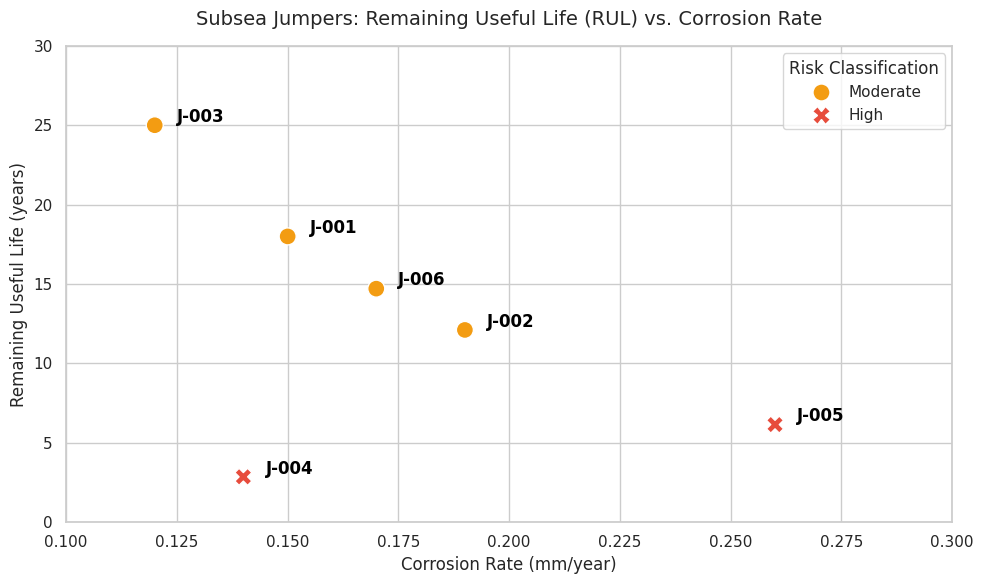

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define Jumper Data
data = {
    "Jumper": ["J-001", "J-002", "J-003", "J-004", "J-005", "J-006"],
    "Current_wall_thickness_mm": [11.2, 10.8, 11.5, 8.9, 10.1, 11.0],
    "Corrosion_rate_mm_year": [0.15, 0.19, 0.12, 0.14, 0.26, 0.17]
}

jumper_df = pd.DataFrame(data)

# 2. RUL Parameters and Calculation
# Assumed minimum wall thickness = 8.5 mm
MIN_WALL_THICKNESS = 8.5

jumper_df["RUL_years"] = (
    (jumper_df["Current_wall_thickness_mm"] - MIN_WALL_THICKNESS)
    / jumper_df["Corrosion_rate_mm_year"]
).round(2)

# 3. Risk Classification based on corrosion rate and remaining life thresholds
# High risk if RUL < 10 years or Corrosion Rate >= 0.20 mm/year; else Moderate
def classify_risk(row):
    if row["RUL_years"] < 10.0 or row["Corrosion_rate_mm_year"] >= 0.20:
        return "High"
    return "Moderate"

jumper_df["Risk_classification"] = jumper_df.apply(classify_risk, axis=1)

# Print the output table
print("=== RUL Calculation Results ===")
print(jumper_df.to_string(index=False))

# Export the results as a CSV file
jumper_df.to_csv("jumper_rul_results.csv", index=False)
print("\nResults successfully saved to 'jumper_rul_results.csv'.")

# 4. Visualization: RUL versus Corrosion Rate
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Plot using scatter plot
ax = sns.scatterplot(
    data=jumper_df,
    x="Corrosion_rate_mm_year",
    y="RUL_years",
    hue="Risk_classification",
    palette={"High": "#e74c3c", "Moderate": "#f39c12"},
    style="Risk_classification",
    s=150,
    markers={"High": "X", "Moderate": "o"}
)

# Annotate the points with jumper names
for i, row in jumper_df.iterrows():
    ax.text(
        row["Corrosion_rate_mm_year"] + 0.005,
        row["RUL_years"] + 0.2,
        row["Jumper"],
        horizontalalignment='left',
        size='medium',
        color='black',
        weight='semibold'
    )

plt.title("Subsea Jumpers: Remaining Useful Life (RUL) vs. Corrosion Rate", fontsize=14, pad=15)
plt.xlabel("Corrosion Rate (mm/year)", fontsize=12)
plt.ylabel("Remaining Useful Life (years)", fontsize=12)
plt.xlim(0.10, 0.30)
plt.ylim(0, 30)
plt.legend(title="Risk Classification", loc="upper right")
plt.tight_layout()

# Save visual chart
plt.savefig("rul_vs_corrosion_rate.png", dpi=300)
plt.show()